---   
 <img align="left" width="75" height="75"  src="https://upload.wikimedia.org/wikipedia/en/c/c8/University_of_the_Punjab_logo.png"> 

<h1 align="center">Department of Data Science</h1>

---
<h3><div align="right">Instructor: Muhammad Arif Butt, Ph.D.</div></h3>    

<br><br>
<h1 align="center">Lec-18: A Quick Recap of Deep Neural Networks</h1>

# Learning agenda of this notebook
1. Recap of Deep Learning Architectures
2. Recap of Gradient Descent Algorithm
3. Recap: Artificial Neural Network (mlp)
4. How Pre-Training of LLMs is Done?
5. Coding Examples for ANN
    - Example 1: Artificial Neural Network using **Scikit-Learn's `MLPRegressor`**
    - Example 2: Artificial Neural Network using **PyTorch Optimizers (SGD, AdaGrad, RMSprop, Adam)**
6. Example Questions to Check your Understanding about Training of a Feed Forward Neural Network

# <span style='background :lightgreen' >1. Recap of Deep Learning Architectures</span>
<div style="text-align:center;">
    <img src="../images/deep-learning-recap.png"
         style="max-width:2000px; width:100%; height:auto; display:inline-block;">
</div>

<h2 align="center"><div class="alert alert-success" style="margin: 20px">ANNs, CNNs, and RNNs serve as foundational building blocks, while architectures such as Variational Autoencoders (VAEs), Generative Adversarial Networks (GANs), Diffusion Models, and Transformers leverage these components to accomplish specific tasks and objectives. </div></h2>

<h2 align="center"><div class="alert alert-success" style="margin: 20px"><b>ANN:</b> Looks at a single snapshot and makes a decision (no context, no spatial awareness)</div></h2>

- **ANN (Artificial Neural Network):**
    - The most basic form: fully connected layers (also called Dense or Multi-Layer Perceptron)
    - Every neuron in one layer connects to every neuron in the next layer.
    - Treats every input independently in sequence one after another. Has no memory of previous inputs, so the NW forgets previous words. This makes it unsuitable for language modeling (NLU, NLG) and sequence prediction.
    - Good for: Simple data, tabular data, basic classification
    
<h2 align="center"><div class="alert alert-success" style="margin: 20px"><b>CNN:</b> Examines an image region by region, building understanding from local to global (spatial awareness)</div></h2>

- **CNN (Convolutional Neural Network):**
    - Specialized for spatial patterns (images, videos)
    - Uses convolution operations to detect features like edges, textures, shapes
    - Key advantage: Processes nearby pixels together, understanding local patterns
  
<h2 align="center"><div class="alert alert-success" style="margin: 20px"><b>RNN:</b> Reads a story word by word, remembering what came before (temporal awareness)</div></h2>

- **RNN (Recurrent Neural Network):**
    - Specialized for sequential/temporal patterns (text, speech, time series)
    - Has memory—can remember previous information in a sequence (LSTM and GRU are variants of RNNs)
    - Works for small sentences like: "The capital of Pakistan is ...."
    - Do not work for long sentences like "Pakistan is a beautiful country with high mountain peaks, a sea coast and deserts, with a population of over 24 crore, and its capital is ....". This is because of the vanishing/exploding gradient problem: during backpropagation the gradient shrinks and earlier information gets lost (explained in Section 4, Step 3)
    - Key advantage: Understands order and context over time

## Generative Architectures
- **Variational Autoencoder (VAE, 2013):** Compresses data into a latent space and reconstructs it. Its building blocks are:
    - For images: VAE uses a CNN-based encoder (convolutional layers to downsample) and a CNN-based decoder (transposed convolutions to upsample)
    - For sequences (text, music): VAE incorporates RNNs in both the encoder and decoder to handle sequential dependencies, producing latent variables that capture temporal structure
    - For tabular data: Uses standard ANN (fully connected layers)
- **Generative Adversarial Network (GAN, 2014):** Generate realistic data samples (commonly images, but also audio, video, tabular) using two competing networks. The Generator creates fake data and the Discriminator classifies whether it is real or fake. Its building  blocks are:
    - Generator: Typically uses transposed CNNs for image generation; can use RNNs for sequential data
    - Discriminator: Acts as a binary classifier — usually CNN-based for images
- **Diffusion Models (2015, popularized in 2020):** Gradually add noise to data during a forward process, then train a model to reverse this process (denoise) to generate new samples. Its building blocks are:
    - Typically built on U-Net style architectures (CNN-based), but these days they are enhanced with attention or Transformer blocks.
    - Encoder path → CNN layers with downsampling to compress
    - Decoder path → CNN layers with upsampling to reconstruct
    - Skip connections → Preserve spatial details across encoder and decoder
    - Timestep embeddings → Inform the model of the current noise level
    - In latent diffusion models like Stable Diffusion, a VAE compresses the image into latent space first, and cross-attention layers condition generation on text
- **Transformer Architecture (2017):** Designed for sequence understanding and generation without recurrence, using a self-attention mechanism instead. The key advantage is efficient capture of long-range relationships. Comes in three variants:
    - Encoder-only (e.g., BERT): For understanding tasks like classification
    - Decoder-only (e.g., GPT): Generates text by predicting the next token
    - Encoder-Decoder (e.g., T5, original Transformer): For tasks like translation and summarization
    - Built using feed-forward layers, positional encoding, and Multi-Head Attention.

# <span style='background :lightgreen' >2. Recap of Gradient Descent Algorithm</span>

<h2 align="center"><div class="alert alert-success" style="margin: 20px"><b>Gradient Descent</b> is a first-order, iterative optimization algorithm for finding a (local) minimum of a differentiable function. It repeatedly takes small steps in the direction <b>opposite</b> to the gradient (slope) at the current point.</div></h2>

## a. Mountain Analogy
<div style="text-align:center;">
    <img src="../images/mountains.png"
         style="max-width:1000px; width:100%; height:auto; display:inline-block;">
</div>

- Imagine you are standing on a mountain in thick fog and want to reach the valley (the lowest point). You cannot see the valley, but you can feel the slope under your feet. So you take a small step downhill, feel the slope again, take another step, and repeat until the ground becomes flat.
- Every gradient descent algorithm has to answer four questions. For a neural network the answers are:

| Question | Mountain analogy | Neural network |
|---|---|---|
| From where to start? | Your starting position on the mountain | Random initial weights and biases |
| Which direction to move? | Downhill, opposite to the slope | Opposite to the gradient (−∂Loss/∂W) |
| How big a step to take? | Length of your stride | learning rate × gradient |
| When to stop? | When the ground becomes flat | After a fixed number of epochs, or when the loss stops decreasing |

## b. Gradient Descent on a 1-D Function
<div style="text-align:center;">
    <img src="../images/GD-33.png"
         style="max-width:1000px; width:100%; height:auto; display:inline-block;">
</div>

- Consider **f(x) = x² + 2x + 2**, whose slope is **f′(x) = 2x + 2**. Its minimum is at x = −1, where the slope is 0.
- **Update rule:** `x_new = x_old − learning_rate × f′(x_old)`
- **Left plot:** starting at x = −9 the slope is negative (−16). Subtracting a negative number moves x to the RIGHT, towards the minimum.
- **Right plot:** starting at x = 8 the slope is positive (+18), so x moves to the LEFT, towards the minimum.
- The steps automatically get smaller near the minimum, because the slope itself gets closer to 0.
- Worked example with learning rate = 0.25, starting at x = −9 (every step halves the distance to the minimum):
```
Step   x_old   f′(x_old) = 2x+2   x_new = x_old − 0.25 × f′(x_old)
 1     −9      −16                −9   − 0.25×(−16) = −5
 2     −5       −8                −5   − 0.25×(−8)  = −3
 3     −3       −4                −3   − 0.25×(−4)  = −2
 4     −2       −2                −2   − 0.25×(−2)  = −1.5
 5     −1.5     −1                −1.5 − 0.25×(−1)  = −1.25   → approaching the minimum at x = −1
```

## c. From One Variable to Millions of Weights
- The loss of a neural network depends on all of its weights at the same time: Loss(W₁, W₂, …, Wₙ). The **gradient** is simply the collection of partial derivatives of the loss with respect to every weight: `∇Loss = [∂Loss/∂W₁, ∂Loss/∂W₂, …, ∂Loss/∂Wₙ]`
- The update rule stays exactly the same; it is just applied to every weight simultaneously:
```
W_new = W_old − learning_rate × ∂Loss/∂W
```
- Computing ∂Loss/∂W for every weight efficiently is the job of **backpropagation** (Section 4, Step 3). Gradient descent then uses those gradients to update the weights (Section 4, Step 4).

## d. Choosing the Learning Rate
<div style="text-align:center;">
    <img src="../images/bad-learning-rate-values.png"
         style="max-width:1000px; width:100%; height:auto; display:inline-block;">
</div>

- Both plots run 10 steps of gradient descent on f(x) = x², starting at x = 10 (minimum at x = 0):
    - **Too small (left, lr = 0.05):** every step only shrinks x by 10%, so after 10 steps x is still 3.49. Training crawls and may not reach the minimum within the given epochs.
    - **Too large (right, lr = 1.1):** every step overshoots the minimum and lands on the other side, farther away than before (x → −1.2 × x). After 10 steps x = 61.9 and the loss is exploding: training **diverges**.
- A good learning rate is large enough to make quick progress but small enough not to overshoot.

## e. Local vs Global Minimum
- A function can have more than one valley. The **global minimum** is the lowest point of the whole function; a **local minimum** is the lowest point of its own valley only. Gradient descent can get stuck in a local minimum.
- Both figures below use the function **f(x) = cos(2πx) + x²**. The x² term makes one big bowl, and the cos(2πx) term adds waves on top of it, so the curve has several valleys.

<img align="right" width="55%" src="../images/local-global-minima-fx.png" style="width:55%; max-width:500px; margin-left:20px;">

### Figure 1: Where does gradient descent end up?
- **Global minimum (green ★):** x = ±0.476, f = −0.762. This is the lowest value of the whole function. There are two of them because f is symmetric about x = 0.
- **Local minimum (red ●):** x = ±1.425, f = 1.140. This is the lowest point of its own valley only.
- **Two runs of gradient descent** with the same algorithm and the same learning rate (0.01). Only the starting point (■) is different:
    - **Green run:** starts at x₀ = 0.9 and rolls down into x = 0.476, a **global minimum**.
    - **Red run:** starts at x₀ = 1.9 and rolls down into x = 1.425, a **local minimum**. It finishes with f = 1.140, much worse than the best possible value of −0.762.
- The two starting points are only 1.0 apart, but the hill at x ≈ 1.05 lies between them, so they roll into different valleys.
- **Lesson:** the starting point decides which valley gradient descent ends up in.

<div style="clear:both;"></div>

### Figure 2: Why does gradient descent stop in a local minimum?
<img align="right" width="55%" src="../images/local-global-minima-slope.png" style="width:55%; max-width:500px; margin-left:20px;">

- Gradient descent cannot see the whole curve. At each step it only feels the **slope** (steepness) of the ground under its feet, shown by the short black lines, and then updates `x_new = x_old − lr × slope`.
- **On the left wall** of the valley, the ground tilts down towards the right (slope < 0). Subtracting a negative number increases x, so GD steps **right**, downhill.
- **On the right wall**, the ground tilts up towards the right (slope > 0). Subtracting a positive number decreases x, so GD steps **left**, downhill.
- **At the bottom**, the ground is flat (slope = 0, red line). Now x_new = x_old − lr × 0 = x_old, so GD **stops**.
- The global minimum is also flat (slope = 0). At the bottom of the local valley, GD feels exactly what it would feel at the global minimum, flat ground, so it has no way of knowing that a deeper valley exists at x = 0.476. **That is why gradient descent gets stuck in a local minimum.**

<div style="clear:both;"></div>

>**What this means for neural networks:**
>- In ANN the loss is a function of millions of weights, and the "starting point" is the set of random initial weights. Which valley training ends up in depends on that starting point.
>- In such high-dimensional loss surfaces, poor local minima are less of a problem than flat regions (plateaus) and saddle points, where the slope is also close to 0 and training slows to a crawl.
>- The noise of mini-batch/stochastic gradient descent (next part) and momentum (Section 4) help the optimizer roll past these flat spots and shallow valleys.

## f. Batch vs Mini-Batch vs Stochastic Gradient Descent
<div style="text-align:center;">
    <img src="../images/gd-types.png"
         style="max-width:900px; width:100%; height:auto; display:inline-block;">
</div>

- The three variants use the same update rule. They differ **only** in how many training samples are used to compute ONE gradient before the weights are updated. For the 2400 training samples used in Section 5:

| Variant | Samples used per update | Weight updates per epoch (N = 2400) | Behaviour |
|---|---|---|---|
| **Batch (full-batch) GD** | all 2400 | 1 | Smooth and accurate gradient, but slow and memory hungry |
| **Mini-Batch GD** | 32 (typically 32–512) | 2400 / 32 = 75 | Practical compromise, used for almost all deep learning including LLMs |
| **Stochastic GD** | 1 | 2400 | Many fast updates, but a noisy, zig-zag path |

- **Epoch** = one complete pass through all training samples. **Iteration (step)** = one weight update.
- In deep learning libraries the name **"SGD"** usually refers to the optimizer's update rule, whatever the batch size. The batch size is decided by how much data you feed in each step (see Section 5).


# <span style='background :lightgreen' >3. Recap: Artificial Neural Network (mlp)</span>

- The figure below summarises the **training loop** that every neural network follows, from the small 5-input regressor in Section 5 to a large language model: (1) forward pass, (2) loss calculation, (3) backpropagation, (4) weight update. Section 4 explains each step in detail.

<div style="text-align:center;">
    <img src="../images/llm-learning3.png"
         style="max-width:1700px; width:100%; height:auto; display:inline-block;">
</div>

# <span style='background :lightgreen' >4. How Pre-Training of LLMs is Done?</span>
<h2 align="center"><div class="alert alert-success" style="margin: 20px"><b>Pre-Training</b> teaches the model EVERYTHING about language from scratch on massive data (terabytes) from random weights</div></h2>
    
## Step 1: Forward Pass/Propagation:
- Forward propagation is the process of passing input values through the neural network layer by layer to produce a predicted output. Each layer takes values from the previous layer, applies a series of learned transformations, and passes the result to the next layer. Simply speaking, each layer takes values from the previous layer and applies three operations: **multiplication** (weights), **addition** (biases), and a non-linear **activation function**. This repeats through all subsequent layers until the final layer produces the model's prediction (e.g., probability distribution over the next token).
```
  Input tokens  →  Embedding  →  Transformer Blocks  →  Output logits
  ["The", "capital", "of", "Pakistan", "is"]             [vocab_size]
                                                               ↓
                                                           Softmax
                                                               ↓
                                                      P("Islamabad") ≈ 0.00002  ← very low!
                                                      (random weights know nothing, so probability is spread
                                                       almost evenly over all 50,000 tokens: 1/50,000 = 0.00002)

```
> **Practice Question 1 at the end of this notebook (Forward Pass)**

## Step 2: Loss Calculation:
- The model's predicted output is compared against the actual target tokens to compute a **loss**, a number that quantifies how wrong the prediction was.
- Loss is HIGH when model assigns LOW probability to the correct next token.
- Loss is ZERO when model is perfectly confident about the correct token.
- Common loss functions used in practice:
    - `mse` (Mean Squared Error): Works for regression tasks, i.e.,  predicting a continuous number (e.g., house price). NOT suitable for next-token prediction because: Output is a probability distribution over 50,000 tokens and MSE does not handle probability distributions well
    - `binary_crossentropy`: Works for binary classification (yes/no, spam/not spam). NOT suitable because next-token prediction has 50,000 possible classes, not just 2
    - `categorical_crossentropy`: Used for multi-class classification and next-token prediction in LLMs to classify which of 50,000 vocabulary tokens comes next
```
Loss = -log( P(correct_token) )
     = -log( P("Islamabad") )
     = -log(0.00002)
     = 10.82   ← very high loss (random prediction was terrible)
```
- Here `log` is the natural log (ln). Useful fact: a freshly initialised LLM starts with a loss of about ln(vocab_size) = ln(50,000) ≈ 10.8, and pre-training drives it down from there.

> **Practice Question 2 at the end of this notebook (Loss Calculation)**

## Step 3: Backward Pass/Propagation: 
<h3 align="center"><div class="alert alert-success" style="margin: 20px"><b>Backpropagation</b>  efficiently calculates how much each weight and bias in the network contributes to the total error (loss) by propagating error signals backward from the output.</div></h3>

- Once the loss is computed, we calculate the **derivative of the loss with respect to every weight** in the ANN/model, these derivatives are called **gradients**.
- `∂Loss/∂W  →  "if I increase this weight slightly, does loss go up or down?"`
- This gradient flows BACKWARDS through every transformer block: `Output layer → MLP layers → Attention layers → Embedding layer`
- Every single weight in the model receives a gradient signal, telling it: "change by this much in this direction"

### Problems that can occur during Backpropagation
- Backpropagation uses the chain rule, so the gradient that reaches an early layer is a **product** of many factors, one per layer it passes through. This leads to two well-known problems:

>- **Vanishing Gradient Problem:** During backpropagation, gradients are multiplied together as they travel backwards through each layer. If these multiplied values are small numbers (less than 1), the gradient shrinks with every layer it passes through, becoming so tiny by the time it reaches the early layers that those weights receive virtually zero update and completely stop learning. This is especially devastating in RNNs processing long sequences where the network must propagate gradients backwards through hundreds of time steps, causing the model to completely forget information from early parts of the sequence.
>- **Exploding Gradient Problem:** The exact opposite of vanishing gradients is Exploding gradients. If the values being multiplied during backpropagation are large numbers (greater than 1), the gradient grows exponentially with every layer it passes through, becoming so enormous by the time the optimizer applies it that weight updates are gigantic and wildly overshoot the minimum. This causes the loss to oscillate uncontrollably or diverge completely, similar to trying to carefully descend a hill but taking steps so large you fly past the bottom and up the other side repeatedly.

> **Practice: Question 3 at the end of this notebook (Backward Propagation)**

## Step 4: Weight Update (Gradient Descent — recall Section 2):
- Once gradients are computed, an optimization algorithm uses them to nudge every weight slightly in the direction that reduces the loss
- The simplest optimization algorithm is Gradient Descent — it updates every weight using the formula:
```
W_new = W_old - learning_rate × gradient
      = W_old - 0.0001 × ∂Loss/∂W
```
<h3 align="center"><div class="alert alert-success" style="margin: 20px"><b>Gradient descent </b> then uses these calculated gradients to adjust the weights and biases in the direction that minimizes that error, taking small steps determined by the learning rate to iteratively improve the model's accuracy. </div></h3>

- After this update: `P("Islamabad") might go from 0.00002 → 0.00003  (tiny improvement)`
- Repeat this for TRILLIONS of tokens across THOUSANDS of GPU-hours and gradually the weights encode all of human language knowledge
- This is why it is called gradient descent, because we descend the loss surface step by step toward the minimum using the gradient as our compass
- The **learning rate** is a critical hyperparameter that controls the size  of each update step:
    - Too **high** → overshoots the minimum → training diverges or oscillates
    - Too **low** → takes too long to converge → training is impractically slow
    - Just **right** → steadily descends toward the local minimum (point of minimum loss) in a reasonable number of steps
- How the weights are actually updated is decided by **two independent choices**:

**Choice 1 — How much data is used to compute each gradient?** (see Section 2f)
<table style="margin-left: 0; margin-right: auto;">
  <thead>
    <tr>
      <th>Variant</th>
      <th>Key Idea</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>BGD</b> (Batch Gradient Descent)</td>
      <td>Update weights using the full dataset at once — accurate but very slow</td>
    </tr>
    <tr>
      <td><b>MBGD</b> (Mini-Batch Gradient Descent)</td>
      <td>Update weights using small batches — a practical compromise between SGD and BGD</td>
    </tr>
    <tr>
      <td><b>SGD</b> (Stochastic Gradient Descent)</td>
      <td>Update weights using one random sample at a time instead of the full dataset</td>
    </tr>
  </tbody>
</table>

**Choice 2 — How is the gradient turned into a weight update?** (the optimizer's update rule; smarter rules converge faster and more reliably than plain gradient descent)
<table style="margin-left: 0; margin-right: auto;">
  <thead>
    <tr>
      <th>Optimizer</th>
      <th>Key Idea</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>Plain GD / SGD</b></td>
      <td>W_new = W_old − lr × gradient — uses only the current gradient</td>
    </tr>
    <tr>
      <td><b>Momentum</b></td>
      <td>Keep a running "velocity" of past gradients — builds up speed in consistent directions and damps zig-zagging</td>
    </tr>
    <tr>
      <td><b>NAG</b> (Nesterov Accelerated Gradient)</td>
      <td>Momentum that looks ahead in the velocity direction before computing the gradient — reduces overshooting</td>
    </tr>
    <tr>
      <td><b>AdaGrad</b> (Adaptive Gradient)</td>
      <td>Give each weight its own learning rate — larger updates for rare features, smaller for frequent ones</td>
    </tr>
    <tr>
      <td><b>RMSProp</b> (Root Mean Square Propagation)</td>
      <td>Fixes AdaGrad's problem of learning rate shrinking to zero — maintains a moving average of squared gradients</td>
    </tr>
    <tr>
      <td><b>Adam</b> (Adaptive Moment Estimation)</td>
      <td>Combines RMSProp + momentum — adapts learning rate per weight AND remembers past gradient directions</td>
    </tr>
    <tr>
      <td><b>AdamW</b> (Adam with decoupled Weight decay)</td>
      <td>Adam with weight decay applied separately from the gradient update — the default choice for training LLMs today</td>
    </tr>
  </tbody>
</table>

- Any update rule from Choice 2 can be combined with any batch size from Choice 1. For example, GPT-style LLMs are trained with **mini-batch AdamW**.
- In practice, **Adam/AdamW** is the most widely used optimizer for training LLMs. It requires storing three extra values per weight in addition to the fp16 working weights and gradients:
<table style="margin-left: 0; margin-right: auto;">
  <thead>
    <tr>
      <th>What is stored</th>
      <th>Precision</th>
      <th>Purpose</th>
    </tr>
  </thead>
  <tbody>
    <tr><td>Working weights</td><td>fp16</td><td>Used in forward and backward pass</td></tr>
    <tr><td>Gradients</td><td>fp16</td><td>Computed during backpropagation</td></tr>
    <tr><td>Master weights</td><td>fp32</td><td>Full-precision copy for stable weight updates</td></tr>
    <tr><td>Momentum (m)</td><td>fp32</td><td>Running average of past gradients — smooths update direction</td></tr>
    <tr><td>Variance (v)</td><td>fp32</td><td>Running average of squared gradients — adapts learning rate per weight</td></tr>
  </tbody>
</table>

> **Practice Question 4 at the end of this notebook (Weight Update with different optimizers)**


# <span style='background :lightgreen' >5. Coding Examples for ANN</span>
## Synthetic Data Generation

In [1]:
#################           Data Generation         ######################

import numpy as np
import pandas as pd

np.random.seed(42)   # Setting a fixed seed ensures the same random numbers are generated every time
N = 3000             # Total number of synthetic weather observations to generate

# Feature Generation (Five Independent Variables / Inputs). Each feature is sampled from a distribution that mimics real-world weather data
# np.random.normal(mean, std_dev, N) → generates N values from a normal distribution
temperature = np.random.normal(18, 7, N)               # °C  — mean 18°C, std 7°C
humidity    = np.random.normal(60, 15, N)              # %   — mean 60%, std 15%
wind_speed  = np.abs(np.random.normal(4, 2, N))        # m/s — always positive (no negative wind speed)
visibility  = np.random.normal(38, 12, N)              # km  — mean 38km, std 12km
dew_point   = temperature - np.random.uniform(2, 8, N) # Dew point is physically related to temperature: # it is always a few degrees below temperature (2–8°C gap)

# Target Generation (Dependent Variable / Output)
# Energy consumption (in kWh) is computed using a non-linear formula that combines all five weather features with different weights
energy = (
    200                            # baseline energy consumption (constant offset)
    + 3.5 * temperature**2         # heating/cooling demand grows quadratically with temperature
    - 0.8 * humidity * temperature # interaction effect: humid heat feels worse, affects HVAC
    + 20  * wind_speed             # wind increases heat loss → more energy to maintain temperature
    - 1.2 * visibility             # low visibility often correlates with cloud cover → less solar gain
    + 15  * dew_point              # higher dew point → more humid air → more cooling energy
    + np.random.normal(0, 80, N)   # adding a random noise to simulate real-world variability
)

# Combine all features and the target into a single pandas DataFrame
df = pd.DataFrame({
    "temperature" : temperature,   # input feature 1
    "humidity"    : humidity,      # input feature 2
    "wind_speed"  : wind_speed,    # input feature 3
    "visibility"  : visibility,    # input feature 4
    "dew_point"   : dew_point,     # input feature 5
    "energy"      : energy         # target variable (what the model will learn to predict)
})

print(f"Dataset shape: {df.shape}")
print(f"Rows: {len(df)}  |  Features: 5  |  Target: energy\n")

# Display the first 5 rows to visually inspect the generated data
df.head()

Dataset shape: (3000, 6)
Rows: 3000  |  Features: 5  |  Target: energy



,temperature,humidity,wind_speed,visibility,dew_point,energy
0,21.476999,31.382887,1.771837,47.184826,17.222230,1443.677358
1,17.032150,47.094225,2.738138,50.880952,11.566202,699.603886
2,22.533820,53.795917,2.115880,43.984279,17.901868,1229.929729
3,28.661209,88.315315,2.904008,14.690028,26.557133,1421.280289
4,16.360926,68.348297,3.571699,36.134931,8.396940,256.971571


In [2]:
#################           Data Preprocessing         ######################
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features (X) and target (y)
X = df[["temperature", "humidity", "wind_speed", "visibility", "dew_point"]].values  # X = what we feed into the model (5 weather columns)
y = df["energy"].values.reshape(-1, 1)   # reshape the output to column vector

# Neural networks train better when all values are in similar range. Use StandardScaler to convert everything to mean=0 and std=1
# fit_transform() does two things in one step:
        #   fit()       → learns the mean and std from the data
        #   transform() → applies the scaling using learned mean and std
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_X.fit_transform(X)   # fit AND transform on input data
y_scaled = scaler_y.fit_transform(y)   # fit AND transform on output column


# Train Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)  # fixed seed so split is always same

print("\nTraining samples :", X_train.shape)   # 2400
print("Testing  samples :", X_test.shape)    # 600


Training samples : (2400, 5)
Testing  samples : (600, 5)


## Example 1: Artificial Neural Network using Scikit-Learn's `MLPRegressor`

<h3 align="center"><div class="alert alert-success" style="margin: 20px"><b>MLPRegressor</b> is a Scikit-Learn class used to implement a Multi-Layer Perceptron (feed-forward neural network) to predict numerical values.</div></h3>


> **Artificial Neural Network Architecture** is not derived from a strict formula, instead it is guided by domain knowledge and experimentation. It normally depends on factors like:

```
| Decision                | Depends On                                                                             |
| ----------------------- | -------------------------------------------------------------------------------------  |
| Input layer neurons     | Number of input features (5), one neuron per feature passes one value into the network |
| Output layer neurons    | Number of predicted variables (1)                                                      |
| Hidden layers count     | Problem complexity and dataset size (4),  more complex problems need more layers       |
| Hidden layers neurons   | Dataset size and model capacity (64, 128, 64, 32)                                      |
| Activation function     | Type of problem and network depth                                                      |
| Network width           | Amount of training data, more data allows wider layers without overfitting             |
```

In [3]:
#################   BUILD AND TRAIN A DEEP NEURAL NETWORK — using MLPRegressor class of scikit-learn  ######################
#################                      Full Batch Gradient Descent                                    ######################
from sklearn.neural_network import MLPRegressor, MLPClassifier
import rich

# Define the ANN architecture and training hyperparameters
fullbatch_sgd = MLPRegressor(
    hidden_layer_sizes = (64, 128, 64, 32),  # number and size of hidden layers — (64,128,64,32) builds 4 hidden layers with 64, 128, 64, 32 neurons respectively (input and output layers are automatic)
    activation         = "relu",             # activation function applied after every hidden layer ("relu" →  max(0,x)), ("tanh" → tanh(x) outputs in [-1, 1] for normalized data), ("identity" → f(x) = x, reduces network to a linear model)
    loss               = "squared_error",    # defines the loss function used during training to measure prediction error and compute gradients for backpropagation. Default is "squared_error", other can be "poisson".
                                             # NOTE: the loss value scikit-learn prints is HALF the MSE, ½ × mean((y − ŷ)²), plus a tiny L2 penalty (alpha=0.0001)
    solver             = "sgd",              # optimization algorithm used to update weights during backpropagation — other options: "adam" (adaptive, faster), "lbfgs" (quasi-Newton, good for small datasets)
    batch_size         = len(X_train),       # Number of training samples used to compute ONE gradient update. This controls WHICH variant of gradient descent is used:
                                                 #  batch_size = len(X_train) → Full Batch GD  (In each epoch, all 2400 samples are passed to calculate the loss. One weight update occur in one epoch. Very stable but very slow)
                                                 #  batch_size = 32         → Mini-Batch GD  (Each weight update uses 32 samples. In each epoch all 2400 samples are passed in 2400/32 = 75 mini-batches, so 75 weight updates occur in one epoch. Fast but slightly noisy)
                                                 #  batch_size = 1          → Stochastic GD  (In each epoch, all 2400 samples are passed to calculate the loss one after another. So 2400 weight updates occur in one epoch. Very fast but very unstable)
    learning_rate_init = 0.01,               # starting step size for weight updates — too large overshoots the minimum, too small learns very slowly
    momentum           = 0.0,                # momentum=0.0 → pure SGD with no momentum: each update uses only the current gradient
                                             # momentum=0.9 → SGD + Momentum: keeps a "velocity" that remembers the direction of past updates and builds up speed.
                                                  #  scikit-learn's rule:  velocity = 0.9 × velocity − learning_rate × gradient,   W_new = W_old + velocity
                                                  #  (90% of the old velocity is carried forward — very common default value; scikit-learn uses Nesterov's variant by default)
    max_iter           = 30,                 # One EPOCH = one complete pass through the entire training dataset.  At 30 epochs with batch_size = full dataset, the optimizer will update the weights exactly 30 times total.
                                                 # Increase this number if the model has not converged (loss still decreasing).  Training may stop earlier if the loss converges
    random_state       = 42,                 # fixed seed for weight initialization and any random operations — ensures identical results every run for reproducibility
    verbose            = True               # if True, prints the training loss after every epoch
)

# Train the model: one-line black box that does everything, we do not see the forward pass, the gradient computation, and the weight updates.
fullbatch_sgd.fit(X_train, y_train.ravel()) # ravel() converts a 2D array into a 1D array by flattening it. Converts y_train(2400, 1) to y_train(2400,) ← 1D array — 2400 values in a flat row

Iteration 1, loss = 0.47507881
Iteration 2, loss = 0.46901583
Iteration 3, loss = 0.46310439
Iteration 4, loss = 0.45730172
Iteration 5, loss = 0.45157724
Iteration 6, loss = 0.44592937
Iteration 7, loss = 0.44034730
Iteration 8, loss = 0.43480803
Iteration 9, loss = 0.42929259
Iteration 10, loss = 0.42380552
Iteration 11, loss = 0.41835858
Iteration 12, loss = 0.41291866
Iteration 13, loss = 0.40748462
Iteration 14, loss = 0.40207986
Iteration 15, loss = 0.39669702
Iteration 16, loss = 0.39133469
Iteration 17, loss = 0.38599642
Iteration 18, loss = 0.38067521
Iteration 19, loss = 0.37538466
Iteration 20, loss = 0.37011524
Iteration 21, loss = 0.36486302
Iteration 22, loss = 0.35962353
Iteration 23, loss = 0.35439073
Iteration 24, loss = 0.34918243
Iteration 25, loss = 0.34401001
Iteration 26, loss = 0.33886990
Iteration 27, loss = 0.33376153
Iteration 28, loss = 0.32868847
Iteration 29, loss = 0.32364982
Iteration 30, loss = 0.31866435


/Users/arif/Documents/genai-course/.venv/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",2400
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.01
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",30
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [4]:
import rich
rich.print(fullbatch_sgd)

MLPRegressor(batch_size=2400, hidden_layer_sizes=(64, 128, 64, 32),
             learning_rate_init=0.01, max_iter=30, momentum=0.0,
             random_state=42, solver='sgd', verbose=True)

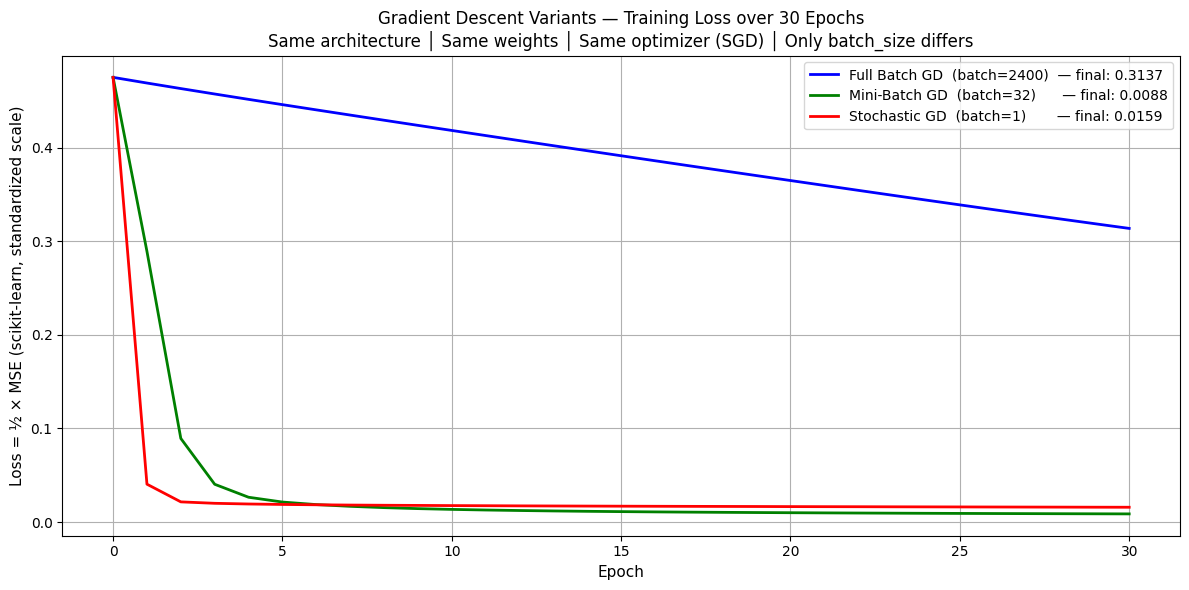

In [5]:
#################   VISUAL REPRESENTATION OF FULL-BATCH VS MINI-BATCH VS STOCHASTIC GRADIENT DESCENT   ######################
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from copy import deepcopy
import warnings
warnings.filterwarnings("ignore")       # suppress all convergence and other warnings

# ── Step 1: Create ONE model and initialize weights ───────────────────────────────
base_model = MLPRegressor(
                        hidden_layer_sizes = (64, 128, 64, 32),
                        activation         = "relu",
                        solver             = "sgd",
                        learning_rate_init = 0.01,
                        momentum           = 0.0,
                        max_iter           = 1,
                        warm_start         = True,
                        batch_size         = len(X_train),
                        random_state       = 42,
                        verbose            = False
                        )
base_model.fit(X_train, y_train.ravel())
initial_loss = base_model.loss_          # loss after the first full-batch epoch — the common starting point of all three curves

# ── Step 2: Deepcopy base model into three separate models ────────────────────────
model_stochastic = deepcopy(base_model) # Update weights using one random sample at a time instead of the full dataset
model_fullbatch  = deepcopy(base_model) # Update weights using the full dataset at once — accurate but very slow
model_minibatch  = deepcopy(base_model) # Update weights using small batches — a practical compromise between SGD and BGD
model_minibatch.batch_size  = 32
model_stochastic.batch_size = 1

# ── Step 3: Train each model epoch by epoch and collect losses ────────────────────
EPOCHS = 30

def collect_losses(model, EPOCHS):
    losses = [initial_loss]
    for epoch in range(EPOCHS):
        model.fit(X_train, y_train.ravel())
        losses.append(model.loss_)
    return losses

losses_fullbatch  = collect_losses(model_fullbatch,  EPOCHS)
losses_minibatch  = collect_losses(model_minibatch,  EPOCHS)
losses_stochastic = collect_losses(model_stochastic, EPOCHS)

# Step 4: Plot 
plt.figure(figsize=(12, 6))

plt.plot(losses_fullbatch,
         label     = f"Full Batch GD  (batch={len(X_train)})  — final: {losses_fullbatch[-1]:.4f}",
         color     = "blue",
         linewidth = 2)

plt.plot(losses_minibatch,
         label     = f"Mini-Batch GD  (batch=32)      — final: {losses_minibatch[-1]:.4f}",
         color     = "green",
         linewidth = 2)

plt.plot(losses_stochastic,
         label     = f"Stochastic GD  (batch=1)       — final: {losses_stochastic[-1]:.4f}",
         color     = "red",
         linewidth = 2)

plt.title("Gradient Descent Variants — Training Loss over 30 Epochs\n"
          "Same architecture │ Same weights │ Same optimizer (SGD) │ Only batch_size differs",
          fontsize = 12)
plt.xlabel("Epoch",                         fontsize = 11)
plt.ylabel("Loss = ½ × MSE (scikit-learn, standardized scale)", fontsize = 11)
plt.legend(fontsize = 10)
plt.grid(True)
plt.tight_layout()
plt.show()

### What do we observe?
- All three models start from the same weights and use the same learning rate (0.01). Only the batch size differs, and therefore the **number of weight updates**:

| Variant | Weight updates per epoch | Weight updates in 30 epochs | Final loss (½ × MSE) |
|---|---|---|---|
| Full Batch GD (batch = 2400) | 1 | 30 | 0.3137 |
| Mini-Batch GD (batch = 32) | 75 | 2,250 | 0.0088 |
| Stochastic GD (batch = 1) | 2400 | 72,000 | 0.0159 |

- **Full-batch GD** descends along a smooth, almost straight line, but with only 30 updates it is still far from the minimum (the `ConvergenceWarning` printed by Example 1 says the same).
- **Stochastic GD** drops the fastest in the first epoch because it has already made 2400 updates. However, each update is based on a single noisy sample, so it keeps bouncing around near the minimum and ends with a higher loss than mini-batch.
- **Mini-batch GD** gives the best result: enough updates to make fast progress, and gradients averaged over 32 samples are far less noisy. This is why mini-batch training is the standard for deep learning.


## Example 2: Artificial Neural Network using PyTorch Optimizers

<h2 align="center"><div class="alert alert-success" style="margin: 20px"><b>PyTorch</b> is an open-source deep learning framework developed by Meta AI that gives you complete control over every step of building, training, and deploying neural networks, from research prototypes to production systems.</div></h2>

### Comparison: MLPRegressor vs PyTorch

| Category | Feature | MLPRegressor (scikit-learn) | PyTorch |
|---|---|---|---|
| ⚙️ **Hardware & Speed** | GPU acceleration | ❌ CPU only | ✅ NVIDIA CUDA, AMD ROCm, Apple MPS |
| | Training speed on large datasets | ❌ 10×–100× slower than GPU | ✅ GPU-accelerated — scales to billions of parameters |
| | Batch data loading | ❌ entire dataset loaded into RAM at once | ✅ DataLoader streams small batches — handles any dataset size |
| 🎮 **Control & Flexibility** | Training loop visibility | ❌ complete black box inside `.fit()` | ✅ every step explicit — forward pass, loss, backprop, update |
| | Custom logic between layers | ❌ impossible | ✅ insert any Python code anywhere in the forward pass |
| | Custom loss functions | ❌ fixed built-in options only | ✅ write any loss function in pure Python |
| | Choice of optimizers | ❌ SGD, Adam, L-BFGS only | ✅ SGD, Adam, AdamW, AdaGrad, RMSprop, and custom |
| 🏗️ **Architecture Support** | Architectures supported | ❌ simple fully-connected MLP only | ✅ MLP, CNN, RNN, LSTM, Transformer, GAN, Diffusion — anything |
| | Dropout & regularization | ❌ very limited (L2 penalty only) | ✅ Dropout, L1, L2, weight decay — fully configurable |
| | Batch / Layer normalization | ❌ not available | ✅ BatchNorm, LayerNorm, GroupNorm — all built-in |
| 🚀 **Production & Deployment** | Save / load model weights | ❌ Python pickle only — fragile | ✅ proper `.pt` checkpoints — weights, optimizer state, epoch |
| | Resume training mid-run | ⚠️ limited — `warm_start=True` continues from the current weights (used in the plot above), but no checkpoint files with optimizer state | ✅ save checkpoint anytime, resume from exact same state |
| | Deploy to production | ❌ not suitable for real systems | ✅ `torch.export`, ONNX export, ExecuTorch for mobile and edge |
| | Used in industry & research | ❌ prototyping and teaching only | ✅ OpenAI · Meta · Tesla · Stability AI · Hugging Face |

>- <p style="color: purple;">PyTorch is powering the world's most important AI systems including OpenAI's GPT/DALL·E, Meta's LLaMA, Stability AI's Stable Diffusion, Tesla's Autopilot, and most models on Hugging Face. (Google's Gemini and Gemma are a notable exception: they are trained with JAX on TPUs.)</p>


### What Stays the Same — What Changes
```
WHAT STAYS IDENTICAL:
  Architecture    : Input(5) → 64 → 128 → 64 → 32 → Output(1)
  Activation      : ReLU on every hidden layer
  Loss function   : Mean Squared Error (MSE)
  Dataset         : same X_train, y_train tensors
  Number of epochs: 30
  Batch size      : FULL batch — all 2400 samples in every update (so 30 weight updates in total)

WHAT CHANGES:Every step of training is now EXPLICIT and VISIBLE:
  MLPRegressor:                    PyTorch:
  ─────────────────                ───────────────────
  model.fit(X, y)         →        model.train()
                                   optimizer.zero_grad()
                                   pred = model(X)             ← forward pass
                                   loss = criterion(pred, y)   ← compute loss
                                   loss.backward()             ← backpropagation
                                   optimizer.step()            ← update weights
```
<p style="color: purple; padding-left: 320px;">These six lines are the <b>universal training loop</b> used in every PyTorch project in the world.</p>

> **Note 1 — "SGD" in PyTorch is only the update rule.** `torch.optim.SGD` computes `W − lr × gradient` (optionally with momentum). Whether training is full-batch, mini-batch or stochastic depends on how much data you pass to the model in each step. Below we pass all of `X_train_t` every epoch, so **all four optimizers run full-batch gradient descent**. For mini-batch training you would loop over `DataLoader(dataset, batch_size=32, shuffle=True)` inside each epoch.
>
> **Note 2 — loss scale.** PyTorch's `nn.MSELoss()` reports the full MSE, whereas scikit-learn reported ½ × MSE. For the same predictions, the loss values in Example 2 are therefore about twice those of Example 1.
>
> **Note 3 — reproducibility.** Every training cell calls `torch.manual_seed(42)` before creating the model, so all four optimizers start from the **same initial weights**. Differences in the final plot then come from the optimizer and its learning rate, not from a lucky initialisation, and you get the same numbers on every run.


In [6]:
##############################    DEFINE ENERGYNET ARCHITECTURE USING TORCH.NN         ###################################
# Define this once — all 4 optimizer experiments reuse this class by calling EnergyNet() to get a fresh model with random weights
################################################################################################################################

import torch          # core PyTorch library — tensors, autograd, math operations
import torch.nn as nn # nn = neural network module — layers, activations, loss functions
import rich

# STEP 1 — CONVERT NUMPY ARRAYS TO PYTORCH TENSORS
# torch.FloatTensor → creates a 32-bit float tensor (matches model weight precision)
X_train_t = torch.FloatTensor(X_train)   # training features  — shape (2400, 5)
y_train_t = torch.FloatTensor(y_train)   # training targets   — shape (2400, 1)
X_test_t  = torch.FloatTensor(X_test)    # test features      — shape (600,  5)
y_test_t  = torch.FloatTensor(y_test)    # test targets       — shape (600,  1)


# STEP 2 — DEFINE THE NEURAL NETWORK ARCHITECTURE
class EnergyNet(nn.Module):
    def __init__(self):
        super().__init__()  # calls nn.Module's own __init__() first. This is mandatory — it sets up PyTorch's internal bookkeeping. Without this line, model.parameters() would not work correctly.
        self.model = nn.Sequential(           # This is the simplest way to build a feedforward network in PyTorch. (a container that chains layers in order)
            nn.Linear(5,   64),  nn.ReLU(),   # Layer 1: 5  inputs  → 64  neurons  (5×64   + 64  = 384   params)
            nn.Linear(64, 128),  nn.ReLU(),   # Layer 2: 64 inputs  → 128 neurons  (64×128 + 128 = 8,320 params)
            nn.Linear(128, 64),  nn.ReLU(),   # Layer 3: 128 inputs → 64  neurons  (128×64 + 64  = 8,256 params)
            nn.Linear(64,  32),  nn.ReLU(),   # Layer 4: 64 inputs  → 32  neurons  (64×32  + 32  = 2,080 params)
            nn.Linear(32,   1)                # Output:  32 inputs  → 1   neuron   (32×1   + 1   = 33    params) NO activation function because this is regression — we want an unbounded continuous prediction, not a value squashed between 0 and 1
        )                                     # Total trainable parameters: 19,073

   # When you write `model(X_train_t)`, PyTorch automatically calls forward(X_train_t) to compute the prediction, builds the computation graph for backpropagation, and returns the output
    def forward(self, x):
        return self.model(x) 

### TRAIN WITH SGD + MOMENTUM
```
W_new = W_old − lr × v,       where v   = 0.9×v + gradient        ← PyTorch's form
```
- Many textbooks (and the Section 3 figure and Question 4) write the "moving-average" form `v = 0.9×v + 0.1×gradient`. Both forms carry 90% of the old velocity forward; PyTorch simply does not scale the new gradient by 0.1, so the same behaviour needs a learning rate about 10× smaller.

In [7]:
EPOCHS     = 30         
losses_sgd = []         

# Instantiate the model — this calls __init__() and builds all layers
torch.manual_seed(42)    # same initial weights for every optimizer → fair comparison and reproducible results
model_sgd = EnergyNet()

optimizer_sgd = torch.optim.SGD(
    model_sgd.parameters(),  # all 19,073 learnable weights and biases updated after every backward pass
    lr       = 0.01,         # step size per weight update — SGD has no adaptive lr scaling so needs a larger lr (0.01) compared to Adam (0.001)
    momentum = 0.9           # keeps 90% of the previous velocity and adds the full current gradient: v = 0.9×v + gradient
                             # momentum=0.0 → pure SGD — each update driven only by current gradient — slow and noisy
)

#print(model_sgd)
for epoch in range(EPOCHS):                       
    model_sgd.train()                             
    optimizer_sgd.zero_grad()                     
    pred = model_sgd(X_train_t)                # Forward pass on ALL 2400 samples (full batch → one weight update per epoch)
    loss = nn.MSELoss()(pred, y_train_t)       # Loss Calculation
    loss.backward()                            # Backward Propagation
    optimizer_sgd.step()                       # Weight Update
    losses_sgd.append(loss.item())             
    #print(f"  Epoch {epoch+1:>3}/{EPOCHS}  │  Loss: {loss.item():.5f}")  # For printing the loss value after every epoch


print(f"\n✅ SGD+Momentum training complete!  Final loss: {losses_sgd[-1]:.5f}")


✅ SGD+Momentum training complete!  Final loss: 0.47050


### TRAIN WITH ADAGRAD

```
W_new = W_old − lr × gradient / √(acc + ε),      where acc = acc + gradient²
```

In [8]:
EPOCHS     = 30          
losses_adagrad = []      

torch.manual_seed(42)    # same initial weights as the other optimizers
model_adagrad = EnergyNet()  

optimizer_adagrad = torch.optim.Adagrad(
    model_adagrad.parameters(),  # all 19,073 learnable weights and biases — each gets its OWN accumulated gradient sum
    lr = 0.01                    # initial lr before adaptive scaling kicks in — set larger than Adam/RMSprop because AdaGrad will shrink it automatically
)

#print(model_adagrad)
for epoch in range(EPOCHS):
    model_adagrad.train()                
    optimizer_adagrad.zero_grad() 
    pred = model_adagrad(X_train_t)            # Forward pass
    loss = nn.MSELoss()(pred, y_train_t)       # Loss Calculation
    loss.backward()                            # Backward Propagation
    optimizer_adagrad.step()                   # Weight Update
    losses_adagrad.append(loss.item())       
   # print(f"  Epoch {epoch+1:>3}/{EPOCHS}  │  Loss: {loss.item():.5f}")

print(f"\n✅ AdaGrad training complete!  Final loss: {losses_adagrad[-1]:.5f}")


✅ AdaGrad training complete!  Final loss: 0.02937


### TRAIN WITH RMSPROP

```
W_new = W_old − lr × gradient / √(v + ε), where v  = 0.99×v + 0.01×gradient²　

```

In [9]:
EPOCHS     = 30          # number of complete passes through the entire training dataset (2400 samples)
losses_rms = []         # empty list to store loss after each epoch — used later to plot the RMSprop loss curve

torch.manual_seed(42)    # same initial weights as the other optimizers
model_rms = EnergyNet()  

optimizer_rms = torch.optim.RMSprop( 
    model_rms.parameters(),  
    lr    = 0.001,           
    alpha = 0.99             
)
#print(model_rms)
for epoch in range(EPOCHS):
    model_rms.train()      
    optimizer_rms.zero_grad()  
    pred = model_rms(X_train_t)                # Forward pass
    loss = nn.MSELoss()(pred, y_train_t)       # Loss Calculation
    loss.backward()                            # Backward Propagation
    optimizer_rms.step()                       # Weight Update   
    losses_rms.append(loss.item())      
   # print(f"  Epoch {epoch+1:>3}/{EPOCHS}  │  Loss: {loss.item():.5f}")

print(f"\n✅ RMSprop training complete!  Final loss: {losses_rms[-1]:.5f}")


✅ RMSprop training complete!  Final loss: 0.02863


### TRAIN WITH ADAM
```
W_new = W_old − lr × m / √(v + ε),     where  m  = 0.9×m + 0.1×gradient,
                                              v  = 0.999×v + 0.001×gradient²　
```
- Simplified: the real Adam also applies a *bias correction*, m̂ = m / (1 − 0.9ᵗ) and v̂ = v / (1 − 0.999ᵗ), which matters most in the first few steps. PyTorch does this for you.


In [10]:
EPOCHS     = 30    
losses_adam = []   

torch.manual_seed(42)    # same initial weights as the other optimizers
model_adam = EnergyNet()

optimizer_adam = torch.optim.Adam(
    model_adam.parameters(),
    lr    = 0.001,        # smaller lr than SGD — Adam's adaptive scaling handles the rest
    betas = (0.9, 0.999), # β1=0.9 controls direction memory, β2=0.999 controls magnitude memory
    eps   = 1e-8          # tiny value added to √v to prevent division by zero
)

#print(model_adam)
for epoch in range(EPOCHS):
    model_adam.train()
    optimizer_adam.zero_grad()
    pred = model_adam(X_train_t)                # Forward pass
    loss = nn.MSELoss()(pred, y_train_t)       # Loss Calculation
    loss.backward()                            # Backward Propagation
    optimizer_adam.step()              # applies full Adam update for all 19,073 weights:
                                       #   m = 0.9×m   + 0.1×grad        → update direction estimate
                                       #   v = 0.999×v + 0.001×grad²     → update magnitude estimate
                                       #   W = W − 0.001 × m / (√v + ε)  → adaptive weight update
    losses_adam.append(loss.item())
    #print(f"  Epoch {epoch+1:>3}/{EPOCHS}  │  Loss: {loss.item():.5f}")
print(f"\n✅ Adam training complete!  Final loss: {losses_adam[-1]:.5f}")


✅ Adam training complete!  Final loss: 0.07780


### Comparison

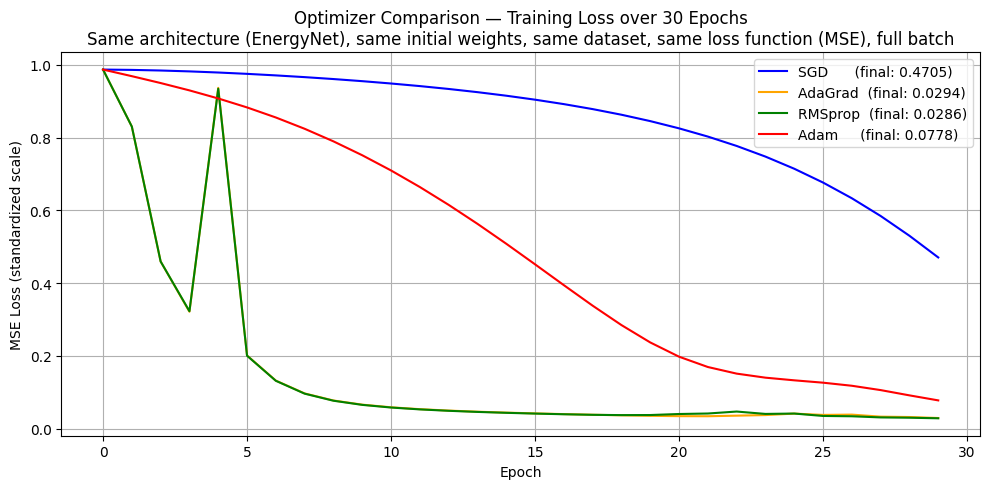

In [11]:
###############    PLOT ALL OPTIMIZERS — LOSS COMPARISON         #######################
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(losses_sgd,     label=f"SGD      (final: {losses_sgd[-1]:.4f})",     color="blue")
plt.plot(losses_adagrad, label=f"AdaGrad  (final: {losses_adagrad[-1]:.4f})", color="orange")
plt.plot(losses_rms,     label=f"RMSprop  (final: {losses_rms[-1]:.4f})",     color="green")
plt.plot(losses_adam,    label=f"Adam     (final: {losses_adam[-1]:.4f})",     color="red")

plt.title("Optimizer Comparison — Training Loss over 30 Epochs\n"
          "Same architecture (EnergyNet), same initial weights, same dataset, same loss function (MSE), full batch")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (standardized scale)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### What do we observe?
- All four models start from the **same initial weights** and are trained **full-batch** for 30 updates. Only the optimizer and its learning rate change:

| Optimizer | Learning rate | Final MSE |
|---|---|---|
| SGD + Momentum | 0.01 | 0.4705 |
| AdaGrad | 0.01 | 0.0294 |
| RMSprop | 0.001 | 0.0286 |
| Adam | 0.001 | 0.0778 |

- **SGD + Momentum is the slowest.** With lr = 0.01 the raw gradients give small steps, and momentum needs several updates to build up speed. The loss is still falling steeply at epoch 30, so it simply needs more updates.
- **AdaGrad and RMSprop almost overlap.** This is not a coincidence. Both divide every gradient by the square root of its accumulated squared gradients, so in the early steps each weight moves by roughly the same amount (≈ 0.01) however small its gradient is. RMSprop's `v` starts out as about 0.01 × AdaGrad's `acc`, so RMSprop with lr = 0.001 takes almost exactly the same steps as AdaGrad with lr = 0.01. The curves only drift apart slowly as RMSprop's 0.99 decay starts to forget old gradients.
- **The spike at epoch 4** comes from those large, equal-sized early steps. They overshoot the minimum, so the loss jumps up. The big gradients at that point are added to the accumulated squares, which shrinks the following steps, and training settles down.
- **Adam descends smoothly.** Its momentum term smooths the direction, and its adaptive scaling sizes each step. With lr = 0.001 it is more cautious than AdaGrad/RMSprop over these first 30 updates.
- **Take-away:** the learning rates differ, and 30 full-batch updates is a very short run. This plot shows how each optimizer behaves at the *start* of training; it is not a general ranking of optimizers.


# <span style='background :lightgreen' >6. Example Questions to Check your Understanding about Training of a Feed Forward Neural Network</span>

### https://arifpucit.github.io/ann-training-simulator/

## Question 1 — Forward Pass
- Consider a single neuron in a small neural network. Compute the output for each part using the given inputs, weights, bias, and activation function. For all parts, you can consider these inputs: **x₁ = 2.0, x₂ = 3.0**
    - **(a)** weights: w₁ = 0.5, w₂ = 0.4, bias = 1.0, activation = **ReLU**
    - **(b)** weights: w₁ = 0.5, w₂ = 0.4, bias = −5.0, activation = **ReLU**
    - **(c)** weights: w₁ = 0.3, w₂ = −0.8, bias = 0.5, activation = **Sigmoid** σ(z) = 1/(1+e⁻ᶻ), use e¹·³ ≈ 3.669
    - **(d)** weights: w₁ = −1.0, w₂ = −1.0, bias = 2.5, activation = **tanh**, use tanh(−2.5) ≈ −0.987
    - **(e)** weights: w₁ = 0.6, w₂ = 0.2, bias = 0.0, activation = **None** (output neuron — regression)

<details>
<summary><b>💡 Click to reveal answer</b></summary>


```
FORMULA:   z = (x₁×w₁) + (x₂×w₂) + bias       a = activation(z)
           x₁ = 2.0,  x₂ = 3.0  for all parts

(a) ReLU — positive z:
    z = (2.0×0.5) + (3.0×0.4) + 1.0
      = 1.0 + 1.2 + 1.0
      = 3.2
    a = ReLU(3.2) = max(0, 3.2) = 3.2
    ReLU is ACTIVE — z is positive so output = z

(b) ReLU — negative z:
    z = (2.0×0.5) + (3.0×0.4) + (−5.0)
      = 1.0 + 1.2 − 5.0
      = −2.8
    a = ReLU(−2.8) = max(0, −2.8) = 0.0
    ReLU is INACTIVE — z is negative so output = 0
    This neuron contributes NOTHING to the next layer

(c) Sigmoid:
    z = (2.0×0.3) + (3.0×−0.8) + 0.5
      = 0.6 − 2.4 + 0.5
      = −1.3
    e⁻⁽⁻¹·³⁾ = e¹·³ ≈ 3.669
    a = σ(−1.3) = 1 / (1 + e¹·³)
                = 1 / (1 + 3.669)
                = 1 / 4.669
                = 0.214
    Output is between 0 and 1 — as expected for Sigmoid

(d) tanh:
    z = (2.0×−1.0) + (3.0×−1.0) + 2.5
      = −2.0 − 3.0 + 2.5
      = −2.5
    a = tanh(−2.5) ≈ −0.987
    

(e) No activation (regression output neuron):
    z = (2.0×0.6) + (3.0×0.2) + 0.0
      = 1.2 + 0.6 + 0.0
      = 1.8
    a = z = 1.8
    No activation applied — raw z is the final prediction
    Output is unbounded — can be any value (−∞ to +∞)
```
</details>


## Question 2 — Loss Calculation
- **(a)** A regression model predicts energy consumption for 4 houses. Compute the MSE and MAE loss:
```
| Sample | Predicted (ŷ) | Actual (y) |
|--------|--------------|------------|
| 1      | 210          | 200        |
| 2      | 185          | 190        |
| 3      | 305          | 300        |
| 4      | 95           | 100        |
```

- **(b)** The following table shows the outputs of a spam classifier for 3 emails. Compute the BCE loss for each sample and the mean BCE. Use natural logs: log(0.9)=−0.105, log(0.8)=−0.223, log(0.4)=−0.916, log(0.6)=−0.511
```
| Sample | True Label (y) | Predicted Prob (p) |
|--------|---------------|-------------------|
| 1      | 1 (spam)      | 0.9               |
| 2      | 0 (not spam)  | 0.2               |
| 3      | 1 (spam)      | 0.4               |
```


- **(c)** A model classifies an image into 3 classes: cat, dog, bird. True label is **cat**. Predicted probabilities after Softmax: p_cat=0.7, p_dog=0.2, p_bird=0.1. Compute the CCE loss. Use the natural log: log(0.7)=−0.357

<details>
<summary><b>💡 Click to reveal answer</b></summary>

```
(a) MSE:
    errors       = [210−200, 185−190, 305−300, 95−100]
                 = [10, −5, 5, −5]
    errors²      = [100, 25, 25, 25]
    MSE          = mean(100, 25, 25, 25)
                 = 175 / 4
                 = 43.75

    MAE:
    |errors|     = [|10|, |−5|, |5|, |−5|]
                 = [10, 5, 5, 5]
    MAE          = mean(10, 5, 5, 5)
                 = 25 / 4
                 = 6.25 
    Careful: MAE (6.25 kWh) and MSE (43.75 kWh²) are in different
    units, so their raw values cannot be compared directly.
    Take the square root of MSE to get back to kWh:
    RMSE         = √43.75 = 6.61 kWh   >   MAE = 6.25 kWh
    RMSE > MAE because squaring gives the one large error (10)
    extra weight — MSE penalises larger errors more heavily

(b) Binary Cross-Entropy:
    Formula: −[ y·log(p) + (1−y)·log(1−p) ]

    Sample 1 (y=1, p=0.9):
      = −[ y×log(p) + (1−y)×log(1−p) ]
      = −[ 1×log(0.9) + (1−1)×log(1−0.9) ]
      = −[ 1×(−0.105) + 0 ]
      = 0.105  (low loss — model was confident and correct)

    Sample 2 (y=0, p=0.2):
      = −[ y×log(p) + (1−y)×log(1−p) ]
      = −[ 0×log(0.2) + (1−0)×log(1−0.2) ]
      = −[ 0×log(0.2) + 1×log(0.8) ]
      = 0.223  (low loss — model correctly predicted not spam)

    Sample 3 (y=1, p=0.4):
      = −[ y×log(p) + (1−y)×log(1−p) ]
      = −[ 1×log(0.4) + (1−1)×log(1−0.4) ]
      = −[ 1×log(0.4) + 0×log(0.6) ]
      = −[ 1×(−0.916) + 0 ]
      = 0.916   (high loss — p = 0.4 < 0.5, so the model predicted
                 NOT spam: a wrong prediction)

    Key insight: Sample 3 has much higher loss because
    the model assigned only 40% probability to the correct class

    Mean BCE over the 3 emails (the single number used for training):
      = (0.105 + 0.223 + 0.916) / 3
      = 1.244 / 3
      = 0.415

(c) Categorical Cross-Entropy:
    Formula: −Σ yᵢ · log(pᵢ)
    True label = cat  →  y_cat=1, y_dog=0, y_bird=0

    loss = −[ 1×log(0.7) + 0×log(0.2) + 0×log(0.1) ]
         = −[ 1×(−0.357) + 0 + 0 ]
         = 0.357

    Key insight: since y=0 for all wrong classes they
    disappear from the sum — CCE always reduces to
    −log(probability assigned to the correct class)
    Lower probability for correct class = higher loss
```
</details>


## Question 3 — Backward Propagation (2 inputs → 2 hidden → 1 output)

- Consider the following neural network with **two input neurons, two hidden neurons, and one output neuron**. There are no bias terms, to keep the calculations simple. The hidden neurons use **ReLU**; the output neuron has **no activation** (plain regression).
    - Inputs:  x₁ = 0.35 , x₂ = 0.90
    - Input → Hidden weights:
        - W₁₃ = 0.1  (x₁ → H₃)   W₂₃ = 0.8  (x₂ → H₃)
        - W₁₄ = 0.4  (x₁ → H₄)   W₂₄ = 0.6  (x₂ → H₄)
    - Hidden → Output weights:
        - W₃₅ = 0.3  (H₃ → O₅)   W₄₅ = 0.9  (H₄ → O₅)
    - Ground truth value:  y = 0.5
    - Loss function:  Loss = (ŷ − y)²     ← squared error; with one sample there is nothing to average, so this *is* the MSE

> **How to read the weight names:** Wᵢₖ is the weight on the arrow going *from* neuron i *to* neuron k. Inputs are neurons 1 and 2, hidden neurons are 3 and 4, the output is 5. So W₂₄ is "input 2 → hidden 4".

<div style="text-align:center;">
    <img src="../images/network_2-2-1.png"
         style="max-width:1000px; width:100%; height:auto; display:inline-block;">
</div>

> **The only calculus you need for this whole question**
>
> 1. **A derivative is a "nudge ratio".** ∂Loss/∂W asks: *if I nudge W up by a tiny amount, how many times bigger (or smaller) is the change in Loss?* A ratio of 0.5 means Loss moves half as much as W. A negative ratio means Loss moves the *opposite* way.
> 2. **The chain rule = multiply the ratios along the path.** If a nudge in W has to travel through several stops to reach the Loss (W → z → a → ŷ → Loss), the total ratio is just the product of the ratio at each stop. Backpropagation is nothing more than multiplying nudge ratios along a path.
> 3. **Three tiny derivative facts:**
>    - The derivative of `c × W` with respect to W is just `c` (the thing multiplying W). Same reason the slope of 3x is 3.
>    - The derivative of `(something)²` is `2 × (something)`.
>    - ReLU is "pass through if positive, else output 0", so its slope is **1** when z > 0 and **0** when z < 0.

<br>

**(a) Keeping the setup above in mind, perform the full Forward Pass — compute z₃, a₃, z₄, a₄, ŷ, and Loss step by step.**

<details>
<summary><b>💡 Click to reveal answer</b></summary>

<div style="text-align:center;">
    <img src="../images/forward_pass_values_2_2_1.png"
         style="max-width:1000px; width:100%; height:auto; display:inline-block;">
</div>

Nothing is being differentiated yet. The forward pass just pushes the numbers left to right: each hidden neuron sums (input × weight), ReLU passes the sum through if it is positive, the output neuron sums (activation × weight), and the loss squares the gap to the target.

```
Forward Pass — left to right:

    HIDDEN NEURON H₃
      z₃ = x₁×W₁₃ + x₂×W₂₃ = 0.35×0.1 + 0.9×0.8 = 0.035 + 0.72 = 0.755
      a₃ = ReLU(z₃)         = ReLU(0.755)                        = 0.755   (z₃ > 0 → ACTIVE → passes through unchanged)

    HIDDEN NEURON H₄
      z₄ = x₁×W₁₄ + x₂×W₂₄ = 0.35×0.4 + 0.9×0.6 = 0.14  + 0.54 = 0.68
      a₄ = ReLU(z₄)         = ReLU(0.68)                         = 0.68    (z₄ > 0 → ACTIVE → passes through unchanged)

    OUTPUT NEURON O₅  (no activation, so ŷ = z₅)
      ŷ  = a₃×W₃₅ + a₄×W₄₅ = 0.755×0.3 + 0.68×0.9 = 0.2265 + 0.612 = 0.8385

    LOSS
      Loss = (ŷ − y)²        = (0.8385 − 0.5)² = (0.3385)²        = 0.1146   (exact: 0.11458225)

    Interpretation: the model predicted 0.8385 but the true value is 0.5
    → the prediction is too HIGH
    → every weight that is pushing ŷ upward will need to come DOWN (we confirm this in part d)
```

> **Why we bother writing z and a separately:** z is the raw weighted sum *before* the activation, a is the value *after* it. Both z's are positive here, so a = z for both hidden neurons. Keep the distinction anyway — in the backward pass the ReLU slope (1 or 0) is decided by the sign of z, not a.
</details>

<br><br><br><br>
**(b) Keeping the setup above in mind, compute the output-layer gradients ∂Loss/∂W₃₅ and ∂Loss/∂W₄₅. These weights connect directly to the output, so only 2 chain-rule steps are needed:**
```
∂Loss/∂W₃₅ = ∂Loss/∂ŷ × ∂ŷ/∂W₃₅
∂Loss/∂W₄₅ = ∂Loss/∂ŷ × ∂ŷ/∂W₄₅
```

<details>
<summary><b>💡 Click to reveal answer</b></summary>

**∂Loss/∂W₃₅**
- ∂Loss/∂ŷ = ∂(ŷ − y)²/∂ŷ = 2(ŷ − y) = 2(0.8385 − 0.5) = 0.677
- ∂ŷ/∂W₃₅ = ∂(a₃W₃₅ + a₄W₄₅)/∂W₃₅ = a₃ = 0.755
- So ∂Loss/∂W₃₅ = 0.677 × 0.755 = **0.5111**

**∂Loss/∂W₄₅**
- ∂Loss/∂ŷ = ∂(ŷ − y)²/∂ŷ = 2(ŷ − y) = 2(0.8385 − 0.5) = 0.677
- ∂ŷ/∂W₄₅ = ∂(a₃W₃₅ + a₄W₄₅)/∂W₄₅ = a₄ = 0.68
- So ∂Loss/∂W₄₅ = 0.677 × 0.68 = **0.4604**

> Output-layer weights connect directly to ŷ, so they need only 2 components instead of 4. The second component is the activation feeding the weight (a₃ or a₄), not the weight itself.

</details>


<br><br><br><br>
**(c) Keeping the setup above in mind, compute the hidden-layer gradients ∂Loss/∂W₁₃, ∂Loss/∂W₂₃, ∂Loss/∂W₁₄, ∂Loss/∂W₂₄. These weights are further from the output, so each gradient must travel back through 4 chain-rule steps:**

```
Hidden-layer weights (4 chain-rule steps each):
  ∂Loss/∂W₁₃ ← [∂z₃/∂W₁₃=x₁] ← [∂a₃/∂z₃ ReLU′] ← [∂ŷ/∂a₃=W₃₅] ← [∂Loss/∂ŷ]
  ∂Loss/∂W₂₃ ← [∂z₃/∂W₂₃=x₂] ← [∂a₃/∂z₃ ReLU′] ← [∂ŷ/∂a₃=W₃₅] ← [∂Loss/∂ŷ]
  ∂Loss/∂W₁₄ ← [∂z₄/∂W₁₄=x₁] ← [∂a₄/∂z₄ ReLU′] ← [∂ŷ/∂a₄=W₄₅] ← [∂Loss/∂ŷ]
  ∂Loss/∂W₂₄ ← [∂z₄/∂W₂₄=x₂] ← [∂a₄/∂z₄ ReLU′] ← [∂ŷ/∂a₄=W₄₅] ← [∂Loss/∂ŷ]
```

<details>
<summary><b>💡 Click to reveal answer</b></summary>

Same game as part (b), just a longer path. Take W₂₄: a nudge in W₂₄ changes z₄, which changes a₄, which changes ŷ, which changes the Loss. Four stops, four ratios. Here is where each ratio comes from:

**∂Loss/∂W₂₄**
- ∂Loss/∂ŷ = ∂(ŷ − y)²/∂ŷ = 2(ŷ − y) = 2(0.8385 − 0.5) = 0.677
- ∂ŷ/∂a₄ = ∂(a₃W₃₅ + a₄W₄₅)/∂a₄ = W₄₅ = 0.9
- ∂a₄/∂z₄ = ReLU′(z₄) = 1, because z₄ = 0.68 > 0
- ∂z₄/∂W₂₄ = ∂(x₁W₁₄ + x₂W₂₄)/∂W₂₄ = x₂ = 0.9
- So ∂Loss/∂W₂₄ = 0.677 × 0.9 × 1 × 0.9 = **0.5484**

**∂Loss/∂W₁₄**
- ∂Loss/∂ŷ = ∂(ŷ − y)²/∂ŷ = 2(ŷ − y) = 2(0.8385 − 0.5) = 0.677
- ∂ŷ/∂a₄ = ∂(a₃W₃₅ + a₄W₄₅)/∂a₄ = W₄₅ = 0.9
- ∂a₄/∂z₄ = ReLU′(z₄) = 1, because z₄ = 0.68 > 0
- ∂z₄/∂W₁₄ = ∂(x₁W₁₄ + x₂W₂₄)/∂W₁₄ = x₁ = 0.35
- So ∂Loss/∂W₁₄ = 0.677 × 0.9 × 1 × 0.35 = **0.2133**

**∂Loss/∂W₁₃**
- ∂Loss/∂ŷ = ∂(ŷ − y)²/∂ŷ = 2(ŷ − y) = 2(0.8385 − 0.5) = 0.677
- ∂ŷ/∂a₃ = ∂(a₃W₃₅ + a₄W₄₅)/∂a₃ = W₃₅ = 0.3
- ∂a₃/∂z₃ = ReLU′(z₃) = 1, because z₃ = 0.755 > 0
- ∂z₃/∂W₁₃ = ∂(x₁W₁₃ + x₂W₂₃)/∂W₁₃ = x₁ = 0.35
- So ∂Loss/∂W₁₃ = 0.677 × 0.3 × 1 × 0.35 = **0.0711**

**∂Loss/∂W₂₃**
- ∂Loss/∂ŷ = ∂(ŷ − y)²/∂ŷ = 2(ŷ − y) = 2(0.8385 − 0.5) = 0.677
- ∂ŷ/∂a₃ = ∂(a₃W₃₅ + a₄W₄₅)/∂a₃ = W₃₅ = 0.3
- ∂a₃/∂z₃ = ReLU′(z₃) = 1, because z₃ = 0.755 > 0
- ∂z₃/∂W₂₃ = ∂(x₁W₁₃ + x₂W₂₃)/∂W₂₃ = x₂ = 0.9
- So ∂Loss/∂W₂₃ = 0.677 × 0.3 × 1 × 0.9 = **0.1828**

> The first component is identical in all four formulas, because every path to the Loss has to pass through ŷ. That's why it only needs to be computed once.
</details>

<br><br><br><br>
**(d)** All six gradients are **positive**. What does a **positive gradient** tell the optimizer to do to each weight? Rank the weights by influence — which weight has the **strongest influence** on the loss, which has the **weakest**, and *why*?


<details>
<summary><b>💡 Click to reveal answer</b></summary>


```
Sign and Magnitude analysis:

    SIGN — every gradient is POSITIVE:
      → a positive nudge ratio means "raise this weight and the loss goes UP"
      → we want the loss to go DOWN, so move every weight the OPPOSITE way: DECREASE it
      → update rule:  W_new = W − lr × (∂Loss/∂W)      (gradient descent)
        The minus sign IS the "go opposite to the gradient" part.

      With lr = 0.1:
        W₂₄: 0.6 − 0.1×0.5484 = 0.5452        W₁₄: 0.4 − 0.1×0.2133 = 0.3787
        W₃₅: 0.3 − 0.1×0.5111 = 0.2489        W₂₃: 0.8 − 0.1×0.1828 = 0.7817
        W₄₅: 0.9 − 0.1×0.4604 = 0.8540        W₁₃: 0.1 − 0.1×0.0711 = 0.0929
      (every weight moves DOWN, pulling ŷ from 0.8385 back toward the target 0.5)

      Sanity check — re-run the forward pass with the new weights:
        z₃ = 0.35×0.0929 + 0.9×0.7817 = 0.7360      a₃ = 0.7360
        z₄ = 0.35×0.3787 + 0.9×0.5452 = 0.6232      a₄ = 0.6232
        ŷ  = 0.7360×0.2489 + 0.6232×0.8540 = 0.1832 + 0.5322 = 0.7154
        Loss = (0.7154 − 0.5)² = 0.0464          ← down from 0.1146 after ONE step
      This matches the sign analysis: ŷ moved toward 0.5 and the loss fell.

    MAGNITUDE — ranked from strongest to weakest influence:

        |∂Loss/∂W₂₄| = 0.5484   ← STRONGEST
        |∂Loss/∂W₃₅| = 0.5111
        |∂Loss/∂W₄₅| = 0.4604
        |∂Loss/∂W₁₄| = 0.2133
        |∂Loss/∂W₂₃| = 0.1828
        |∂Loss/∂W₁₃| = 0.0711   ← weakest

      A gradient is a PRODUCT of nudge ratios. A product is big when every factor is
      big, and small when ANY factor is small. That is the whole story of the ranking.

      WHY W₂₄ is strongest:
        Its gradient is 0.677 × W₄₅(0.9) × 1 × x₂(0.9) = 0.5484. It stacks the two
        biggest factors in the network — it carries the LARGE input x₂ = 0.9
        through the STRONG downstream path W₄₅ = 0.9. Nothing along its path
        shrinks the signal.

      WHY W₁₃ is weakest:
        Its gradient is 0.677 × W₃₅(0.3) × 1 × x₁(0.35) = 0.0711. It carries the
        SMALL input x₁ = 0.35 through the WEAK downstream path W₃₅ = 0.3.
        The signal gets diluted twice.

      WHY the output weights land in the middle:
        They have only TWO factors (0.677 × aₖ), so nothing dilutes them much,
        but the activations (0.755, 0.68) are smaller than the 0.9 × 0.9 combination
        that W₂₄ enjoys. W₃₅ beats W₄₅ only because a₃ > a₄.

      GENERAL PRINCIPLE:
        • An OUTPUT-layer weight's gradient scales with the activation feeding it
          (∂Loss/∂ŷ × aₖ).
        • A HIDDEN-layer weight's gradient scales with BOTH its input value xᵢ AND
          the strength of its path to the output (Wₖ₅) AND whether its neuron is
          alive (ReLU′). Big inputs + strong downstream connections amplify the
          gradient; small ones shrink it; a dead neuron zeroes it.
        • This is exactly why gradients get "diluted" as they travel backward:
          each extra layer adds another factor to the product. When those factors
          are mostly below 1 (as 0.677, 0.3 and 0.35 are here), the product shrinks
          toward zero for the early layers — the seed of the vanishing-gradient
          problem in deep networks.
```

> **Test yourself:** suppose W₂₃ had been −0.8 instead of 0.8, so that z₃ = 0.35×0.1 + 0.9×(−0.8) = 0.035 − 0.72 = −0.685 came out below zero. Without recomputing anything else, what happens to ∂Loss/∂W₁₃, ∂Loss/∂W₂₃ and ∂Loss/∂W₃₅? *(Answer: all three become exactly 0. ReLU′(z₃) = 0 is one of the factors in the products for ∂Loss/∂W₁₃ and ∂Loss/∂W₂₃, so both are 0. And a₃ = ReLU(−0.685) = 0 is the factor in ∂Loss/∂W₃₅ = ∂Loss/∂ŷ × a₃, so it is 0 too. H₃ is "dead" for this sample: neither the weights coming into it nor the weight leaving it receive any update. H₄ is unaffected, so its weights still learn.)*
</details>

## Question 4 — Weight Update
- A weight currently has value **W = 0.5** and its gradient is **∂Loss/∂W = −0.4**. Use **learning rate lr = 0.1** for all parts, and the update formulas shown in the Section 3 figure (Step 4).
    - **(a) SGD (plain):**  Compute W_new
    - **(b) SGD + Momentum:**  Previous velocity v = 0.2. Compute new v then W_new. Use the moving-average form v = 0.9×v + 0.1×gradient
    - **(c) AdaGrad:**  Previous accumulated sum acc = 0.5. Compute new acc then W_new. Use √0.67 ≈ 0.819, ε = 0.01
    - **(d) RMSprop:**  Previous moving average v = 0.3. Compute new v then W_new. Use   √0.3086 ≈ 0.556, ε = 0.01
    - **(e) Adam:**  Previous m = 0.1, previous v = 0.2. Compute new m, new v, then W_new. Use √0.2100 ≈ 0.458, ε = 0.01

<details>
<summary><b>💡 Click to reveal answer</b></summary>

```
Given:  W = 0.5,  gradient = −0.4,  lr = 0.1

(a) SGD (plain):
    W_new = W − lr × gradient
          = 0.5 − 0.1 × (−0.4)
          = 0.5 + 0.04
          = 0.54 
    Gradient is negative → weight INCREASES

(b) SGD + Momentum  (v_old = 0.2):
    v_new = 0.9 × v_old  +  0.1 × gradient
          = 0.9 × 0.2    +  0.1 × (−0.4)
          = 0.18 − 0.04
          = 0.14
    W_new = W − lr × v_new
          = 0.5 − 0.1 × 0.14
          = 0.5 − 0.014
          = 0.486 
    Notice: plain SGD moved W UP (0.5 → 0.54), but momentum moves
    it DOWN (0.5 → 0.486). The previous velocity (+0.2) pointed
    the other way, and even after decaying to 0.18 it outweighs
    the new contribution 0.1 × (−0.4) = −0.04. Momentum keeps the
    weight moving in its OLD direction until enough opposite
    gradients accumulate to turn it around.

    (PyTorch's form v = 0.9×v + gradient does not scale the new
     gradient by 0.1:  v = 0.18 − 0.4 = −0.22,
     W_new = 0.5 − 0.1 × (−0.22) = 0.522 → here the fresh gradient
     outweighs the old velocity and W moves UP.)

(c) AdaGrad  (acc_old = 0.5):
    acc_new = acc_old + gradient²
            = 0.5 + (−0.4)²
            = 0.5 + 0.16
            = 0.66
    W_new = W − lr × gradient / √(acc_new + ε)
          = 0.5 − 0.1 × (−0.4) / √(0.66 + 0.01)
          = 0.5 − 0.1 × (−0.4) / √0.67
          = 0.5 − 0.1 × (−0.4) / 0.819
          = 0.5 + 0.04884
          = 0.549  
    Effective lr = 0.1 / 0.819 = 0.122 — scaled UP this time,
    because √(acc + ε) = 0.819 is less than 1.
    acc only ever grows (it adds gradient² at every step), so the
    effective lr SHRINKS at every step. Once √(acc + ε) passes 1 it
    falls below the base lr of 0.1 and keeps heading towards 0

(d) RMSprop  (v_old = 0.3):
    v_new = 0.99 × v_old  +  0.01 × gradient²
          = 0.99 × 0.3    +  0.01 × (−0.4)²
          = 0.297 + 0.01 × 0.16
          = 0.297 + 0.0016
          = 0.2986
    W_new = W − lr × gradient / √(v_new + ε)
          = 0.5 − 0.1 × (−0.4) / √(0.2986 + 0.01)
          = 0.5 − 0.1 × (−0.4) / √0.3086
          = 0.5 + 0.04 / 0.556
          = 0.5 + 0.072
          = 0.572 
    v changes very slowly (0.3 → 0.2986) due to 0.99 decay
    keeping learning rate stable — unlike AdaGrad which
    keeps growing acc and eventually stops learning

(e) Adam  (m_old = 0.1,  v_old = 0.2):
    (Simplified: real Adam also applies bias correction,
     m̂ = m / (1 − 0.9ᵗ) and v̂ = v / (1 − 0.999ᵗ), which matters most
     in the first few steps. We skip it to keep the arithmetic short.)

    m_new = 0.9 × m_old   +  0.1 × gradient
          = 0.9 × 0.1     +  0.1 × (−0.4)
          = 0.09 − 0.04
          = 0.05

    v_new = 0.999 × v_old  +  0.001 × gradient²
          = 0.999 × 0.2    +  0.001 × (−0.4)²
          = 0.1998 + 0.001 × 0.16
          = 0.1998 + 0.00016
          = 0.19996  ≈ 0.2000

    W_new = W − lr × m_new / √(v_new + ε)
          = 0.5 − 0.1 × 0.05 / √(0.2000 + 0.01)
          = 0.5 − 0.005 / √0.2100
          = 0.5 − 0.005 / 0.458
          = 0.5 − 0.0109
          = 0.489  
    m smooths the gradient direction (0.1 → 0.05). m is still
    POSITIVE, so like momentum, Adam moves W DOWN even though
    the current gradient is negative
    v barely changes (0.2 → 0.19996) — very stable magnitude estimate
    Adam produces a small, cautious update

─────────────────────────────────────────────────────────
Final Comparison (W_old = 0.5, gradient = −0.4, lr = 0.1):

  Optimizer      W_new    Step (W_new − W_old)   Direction
  SGD Plain      0.540    +0.040                 UP    follows the current gradient
  SGD+Momentum   0.486    −0.014                 DOWN  old velocity wins
  AdaGrad        0.549    +0.049                 UP    effective lr 0.122 > 0.1
  RMSprop        0.572    +0.072                 UP    LARGEST step (effective lr 0.1/0.556 = 0.180)
  Adam           0.489    −0.011                 DOWN  SMALLEST step (m is still positive)

  Momentum and Adam remember the DIRECTION of past gradients (v, m),
  so they can keep moving against the current gradient. AdaGrad and
  RMSprop only remember the SIZE of past gradients (gradient²), so they
  can make the step bigger or smaller but never reverse it: like plain
  SGD, they always follow the current gradient.
─────────────────────────────────────────────────────────
```
</details>